# Kim 2023 

The data comes from [Integrative analysis of single-cell RNA-seq and ATAC-seq reveals heterogeneity of induced pluripotent stem cell-derived hepatic organoids
](https://www.sciencedirect.com/science/article/pii/S2589004223017522) paper (let's call it Kim23).

The study used expandable human liver organoids generated from induced pluripotent stem cells (iPSCs). Organoids were cultured in two main conditions:
Hepatic Medium (HM): expandable condition used for maintenance, and Differentiation Medium (DM): more differentiated condition applied to induce further maturation.   
Four organoid samples were analyzed for both sequencing types – two biological replicates for the HM condition and two biological replicates for the DM condition. A total of 39,300 cells were analyzed by scRNA-seq  and ~37,000 nuclei by scATAC-seq.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

print(sys.version)

3.13.2 | packaged by conda-forge | (main, Feb 17 2025, 14:10:22) [GCC 13.3.0]


In [2]:
os.chdir('/home/kl467102/thesis')

### Here we load the already preprocessed data

In [8]:
#preprocessed adata:
preprocessed_adata_path = '/home/kl467102/thesis/BEELINE/inputs/kim23-hm1/kim23-hm1.h5ad'

In [9]:
adata_rna = sc.read_h5ad(preprocessed_adata_path)
adata_rna.X = adata_rna.layers['counts']

In [16]:
full_budget = int(adata_rna.X.sum())
full_budget

72171000

### SAMPLING


In [12]:
def sample_cells(
        adata,
        *,
        n_cells=None,      # absolute number
        frac=None,         # fraction in (0, 1]
        seed=420
    ):
    """
    Returns a copy of `adata` containing a random subset of cells.

    Give **exactly one** of
      • n_cells : int      (e.g. 3000)  
      • frac    : float    (e.g. 0.10 for 10 %)
    """
    if (n_cells is None) == (frac is None):
        raise ValueError("specify *either* n_cells or frac, not both")

    rng = np.random.default_rng(seed)
    total = adata.n_obs

    if frac is not None:
        if not (0 < frac <= 1):
            raise ValueError("`frac` must be in (0, 1]")
        n_cells = int(round(total * frac))

    if n_cells > total:
        raise ValueError(f"requested {n_cells} cells but adata only has {total}")

    keep = rng.choice(total, size=n_cells, replace=False)
    return adata[keep].copy()

    
def sample_reads(adata, *, depth_factor=None, target_umi=None, seed=420):
    """
    Returns a copy of `adata` with down-sampled counts.

    Either give
      depth_factor ∈ (0,1]   (same fraction for every cell)      or
      target_umi   > 0       (absolute UMIs wanted per cell)
    """
    if (depth_factor is None) == (target_umi is None):
        raise ValueError("specify exactly one of depth_factor or target_umi")

    rng = np.random.default_rng(seed)
    X   = adata.X.copy()

    if sp.issparse(X):                 # handle sparse matrices efficiently
        X = X.tocoo()
        if depth_factor is not None:
            p = depth_factor
            X.data = rng.binomial(X.data.astype(np.int64), p)
        else:
            totals = np.asarray(adata.X.sum(axis=1)).ravel()          # per-cell UMIs
            p_cell = np.minimum(1., target_umi / totals)              # per-cell probs
            X.data = rng.binomial(X.data.astype(np.int64), p_cell[X.row])
        X = X.tocsr()
    else:                              # dense matrix
        if depth_factor is not None:
            X = rng.binomial(X.astype(np.int64), depth_factor)
        else:
            totals = X.sum(1, keepdims=True)
            p_cell = np.minimum(1., target_umi / totals)
            X = rng.binomial(X.astype(np.int64), p_cell)

    out = adata.copy()
    out.X = X
    out.obs["n_counts_sim"] = np.asarray(X.sum(axis=1)).ravel()       # keep track
    return out


In [ ]:
import numpy as np
import scipy.sparse as sp
import anndata as ad
import warnings


def sample_proportional_budget(
    adata,
    *,
    budget,
    n_cells,
    seed=420
):
    """
    Returns a copy of `adata` subsampled to a fixed budget,
    maintaining proportional read depths across cells.

    The budget is the target total number of UMIs across all sampled cells.
    Downsampling is applied as a single fraction to all cells, preserving
    the relative differences in their original library sizes.

    Parameters
    ----------
    adata
        The AnnData object to subsample.
    budget
        The target total number of UMIs for the experiment (e.g., 10_000_000).
    n_cells
        The number of cells to sample for this experiment.
    seed
        A random seed for reproducibility.
    """
    if n_cells > adata.n_obs:
        raise ValueError(
            f"Requested {n_cells} cells but the object only has {adata.n_obs}."
        )

    # 1. Subsample to the desired number of cells
    adata_n_cells = sample_cells(adata, n_cells=n_cells, seed=seed)

    # 2. Calculate the total UMIs currently in the subsampled object
    current_total_umis = adata_n_cells.X.sum()

    # 3. Calculate the single downsampling factor for all cells
    # This is the fraction of reads to keep to meet the budget.
    depth_factor = budget / current_total_umis
    print(f"Budget ({budget}), n_cells: {n_cells}, calculated depth factor: {depth_factor}.")

    # Handle the case where the budget is larger than available reads
    if depth_factor > 1.0:
        warnings.warn(
            f"Budget ({int(budget)}) is higher than current UMIs ({int(current_total_umis)}) "
            f"in the {n_cells} sampled cells. No reads will be added. "
            "Returning cells with original read counts."
        )
        # In this scenario, we just return the sampled cells without downsampling.
        return adata_n_cells

    # 4. Downsample all selected cells by this single fraction
    adata_downsampled = sample_reads(
        adata_n_cells,
        depth_factor=depth_factor,
        seed=seed
    )

    # You can verify the result (optional)
    final_umis = adata_downsampled.X.sum()
    print(f"Target budget: {budget}, Final UMIs: ~{int(final_umis)}")

    return adata_downsampled

In [14]:


# ─── STEP 2: identify & combine HVGs ──────────────────────────────────────────

def build_hvg_subset(ad, n_top_hvg, all_known_tfs, include_hv_tfs):

    adata =ad.copy()
        # Normalize and logarithmize
    adata.raw = adata.copy()
    adata.layers['counts'] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    print("\n--- STEP 2: Identifying HVGs ---")
    # Default HVGs
    sc.pp.highly_variable_genes(adata, n_top_genes=None)
    default_mask = adata.var['highly_variable'].copy()
    n_default = default_mask.sum()
    print(f"Default HVGs: {n_default}")
    # Cutoff HVGs
    sc.pp.highly_variable_genes(adata, n_top_genes=n_top_hvg)
    cutoff_mask = adata.var['highly_variable'].copy()
    n_cutoff = cutoff_mask.sum()
    print(f"Top {n_top_hvg} HVGs: {n_cutoff}")
    # Include TFs
    tf_mask = adata.var_names.isin(all_known_tfs)
    tf_in_default = default_mask & tf_mask
    n_tf_default = tf_in_default.sum()
    print(f"TFs in default HVGs: {n_tf_default}")
    combined = cutoff_mask.copy()
    if include_hv_tfs:
        combined |= tf_in_default
        added = combined.sum() - n_cutoff
        print(f"Including additional {added} TFs → total combined HVGs: {combined.sum()}")
    ad_hvg = adata[:, combined].copy()
    expr_df = pd.DataFrame(
        ad_hvg.X.toarray(),
        index=ad_hvg.obs_names,
        columns=ad_hvg.var_names
    ).T
    print(f"HVG subset shape: cells={ad_hvg.n_obs}, genes={ad_hvg.n_vars}\n")
    return ad_hvg, expr_df

# ─── STEP 3: filter & save network + expression ───────────────────────────────
def filter_and_save(ad_sub, expr_df, net_df, cfg, key):
    print("--- STEP 3: Filtering network & saving outputs ---")
    budget_name, strategy, n_cells = key
    # Dataset part with hyphens: DATASET-CELLS-READS
    dataset_part = f"{cfg['dataset_name']}-{budget_name}-S{int(strategy*100)}-{n_cells}cells"
    # Suffix: _NETWORK_NUMGENES(-TFs)
    suffix = (
        f"_{cfg['network_name']}"
        f"_{cfg['n_top_hvg']}"
        + ("TFs" if cfg['include_hv_tfs'] else "")
    )
    prefix = cfg['output_dir'] / f"{dataset_part}{suffix}"
    prefix.parent.mkdir(parents=True, exist_ok=True)

    # filter network
    df = net_df[
        net_df.Gene1.isin(ad_sub.var_names) &
        net_df.Gene2.isin(ad_sub.var_names)
    ].copy()
    df = df[df.Gene1 != df.Gene2].drop_duplicates()

    # save
    expr_file = Path(f"{prefix}--ExpressionData.csv")
    net_file  = Path(f"{prefix}--network.csv")
    expr_df.to_csv(expr_file)
    df.to_csv(net_file, index=False)

    # summary stats
    tfs = set(df.Gene1)
    all_nodes = set(df.Gene1) | set(df.Gene2)
    n_tfs = expr_df.index.isin(tfs).sum()
    n_genes = len(all_nodes)
    n_edges = len(df)
    density = n_edges / (n_tfs * (n_genes - 1))

    print(f"{budget_name}, {n_cells} cells → genes:{ad_sub.n_vars}, "
          f"tfs:{n_tfs}, edges:{n_edges}, density:{density:.3f}")

    return {"expr": expr_file, "network": net_file}



In [32]:

# Run it:
# ─── Config ────────────────────────────────────────────────────────────────────

tf_file = '/home/kl467102/Beeline-238/inputs/hHep/human-tfs.csv'
network_file = '/home/kl467102/string_dir/9606_protein_links_gene_names_combined_score_700.csv'
network_name = 'STRING12'
output_dir = Path('/home/kl467102/Beeline-238/inputs/kim23_budget_constrained')


In [36]:
adata_full = adata_rna.copy()
total_umis_in_adata  = adata_full.X.sum()
total_cells  = adata_full.n_obs
avg_umi_per_cell = total_umis_in_adata / total_cells
umi_counts_per_cell = adata_full.X.sum(axis=1).A1
median_umi_per_cell = np.median(umi_counts_per_cell)

budgets = {
    "Nano10":   int(total_umis_in_adata * 0.10),
    "Low25":    int(total_umis_in_adata * 0.25),
    "Medium50": int(total_umis_in_adata * 0.50),
    "High75":   int(total_umis_in_adata * 0.75)
}

num_points = 10
min_cells = 500


In [38]:
budget_cfg = {
    
    # --- Parameters for the new experiment ---
    'budgets': budgets,
    'strategy_points': np.linspace(0, 1, 10), # 8 points from Depth-First to Cells-First
    # -----------------------------------------
    
    'seed': 420,
    'n_top_hvg': 1000,
    'include_hv_tfs': True,
    'min_depth_threshold': 500, # Min avg UMIs/cell to be considered a valid experiment
    
    # Static config 
    'dataset_name': dataset_name,
    'output_dir': output_dir,
    'network_name': network_name

}
# Load auxiliary data

all_known_tfs = pd.read_csv(tf_file, header=None).iloc[:,0].tolist()
network_df = pd.read_csv(network_file)

In [39]:
print("Starting experimental pipeline...")
results = {}
adata_sims = {}
pbar_budgets = tqdm(budget_cfg['budgets'].items(), desc="Budgets")
results_list = [] 

for budget_name, budget_value in pbar_budgets:
    # A. Find the EXPECTED min number of cells for this budget
    min_n_cells_expected = int(budget_value / avg_umi_per_cell)

    if min_n_cells_expected >= total_cells:
        pbar_budgets.set_postfix_str(f"Skipping {budget_name}, needs >{total_cells} cells.")
        continue

    # B. Find the max number of cells that meets the min depth threshold
    max_n_cells_for_budget = int(budget_value / budget_cfg['min_depth_threshold'])
    max_n_cells_final = min(total_cells, max_n_cells_for_budget)

    if min_n_cells_expected >= max_n_cells_final:
        pbar_budgets.set_postfix_str(f"Skipping {budget_name}, no valid cell range.")
        continue

    # C. Loop over the STRATEGY points
    pbar_strategies = tqdm(
        budget_cfg['strategy_points'],
        desc=f"Strategies for {budget_name}",
        leave=False
    )
    for strategy in pbar_strategies:

        n_cells = int(min_n_cells_expected + strategy * (max_n_cells_final - min_n_cells_expected))


        pbar_strategies.set_postfix_str(f"{n_cells} cells")

        # E. Run the simulation
        adata_sim = sample_proportional_budget(
            adata_full,
            budget=budget_value,
            n_cells=n_cells,
            seed=budget_cfg['seed']
        )
        
        adata_sims[(budget_name, strategy, n_cells)] = adata_sim
        final_umis = int(np.asarray(adata_sim.X.sum()).ravel().sum()) 
        actual_depth_factor = final_umis / total_umis_in_adata
        mean_umi = final_umis / adata_sim.n_obs
        # F. Run the analysis pipeline
        ad_hvg, expr_df = build_hvg_subset(
            adata_sim,
            budget_cfg['n_top_hvg'],
            all_known_tfs,
            budget_cfg['include_hv_tfs']
        )
        
        key = (budget_name, round(strategy, 2), n_cells)
        io = filter_and_save(ad_hvg, expr_df, network_df, budget_cfg, key)
        results[key] = io
        results_list.append({
            'budget_name': budget_name,
            'strategy': round(strategy, 2),
            'n_cells': n_cells,
            'actual_frac_cells': n_cells / total_cells,
            'actual_depth_factor': actual_depth_factor,
            'expr_file': io['expr'],
        })
print("\n\n✅ Pipeline finished successfully!")
# if results:
#     results_summary = pd.DataFrame(
#         results.keys(),
#         columns=['budget_name', 'strategy', 'n_cells']
#     )
#     print("Summary of simulations run:")
#     print(results_summary)
# else:
#     print("No simulations were run. Please check your parameters.")

if results_list:
    results_summary = pd.DataFrame(results_list)
    print("Summary of simulations run:")
    print(results_summary[['budget_name', 'strategy', 'n_cells', 'actual_depth_factor']])
else:
    print("No simulations were run. Please check your parameters.")



Starting experimental pipeline...


Budgets:   0%|                                                                                                                                                                           | 0/4 [00:00<?, ?it/s]/tmp/ipykernel_62763/1725482693.py:50: UserWarning: Budget (7217099) is higher than current UMIs (6867891) in the 765 sampled cells. No reads will be added. Returning cells with original read counts.
  warnings.warn(



--- STEP 2: Identifying HVGs ---
Default HVGs: 2420
Top 1000 HVGs: 1000
TFs in default HVGs: 229
Including additional 161 TFs → total combined HVGs: 1161
HVG subset shape: cells=765, genes=1161

--- STEP 3: Filtering network & saving outputs ---


Nano10, 765 cells → genes:1161, tfs:511, edges:3638, density:0.014
Target budget: 7217099, Final UMIs: ~7218441

--- STEP 2: Identifying HVGs ---
Default HVGs: 2297
Top 1000 HVGs: 1000
TFs in default HVGs: 218
Including additional 174 TFs → total combined HVGs: 1174
HVG subset shape: cells=1530, genes=1174

--- STEP 3: Filtering network & saving outputs ---


Nano10, 1530 cells → genes:1174, tfs:447, edges:2562, density:0.013
Target budget: 7217099, Final UMIs: ~7217477

--- STEP 2: Identifying HVGs ---
Default HVGs: 2286
Top 1000 HVGs: 1000
TFs in default HVGs: 220
Including additional 157 TFs → total combined HVGs: 1157
HVG subset shape: cells=2295, genes=1157

--- STEP 3: Filtering network & saving outputs ---


Nano10, 2295 cells → genes:1157, tfs:440, edges:1970, density:0.010
Target budget: 7217099, Final UMIs: ~7217087

--- STEP 2: Identifying HVGs ---
Default HVGs: 2429
Top 1000 HVGs: 1000
TFs in default HVGs: 223
Including additional 168 TFs → total combined HVGs: 1168
HVG subset shape: cells=3060, genes=1168

--- STEP 3: Filtering network & saving outputs ---


... (42 outputs left out)

High75, 7226 cells → genes:1074, tfs:469, edges:3484, density:0.016
Target budget: 54128244, Final UMIs: ~54130539

--- STEP 2: Identifying HVGs ---
Default HVGs: 1479
Top 1000 HVGs: 1000
TFs in default HVGs: 140
Including additional 76 TFs → total combined HVGs: 1076
HVG subset shape: cells=7439, genes=1076

--- STEP 3: Filtering network & saving outputs ---


High75, 7439 cells → genes:1076, tfs:467, edges:3882, density:0.018
Target budget: 54128244, Final UMIs: ~54127755

--- STEP 2: Identifying HVGs ---
Default HVGs: 1451
Top 1000 HVGs: 1000
TFs in default HVGs: 135
Including additional 73 TFs → total combined HVGs: 1073
HVG subset shape: cells=7652, genes=1073

--- STEP 3: Filtering network & saving outputs ---


Budgets: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [09:04<00:00, 136.12s/it]

High75, 7652 cells → genes:1073, tfs:466, edges:3678, density:0.017


✅ Pipeline finished successfully!
Summary of simulations run:
   budget_name  strategy  n_cells  actual_depth_factor
0       Nano10      0.00      765             0.095161
1       Nano10      0.11     1530             0.100019
2       Nano10      0.22     2295             0.100005
3       Nano10      0.33     3060             0.100000
4       Nano10      0.44     3825             0.099974
5       Nano10      0.56     4591             0.100013
6       Nano10      0.67     5356             0.100003
7       Nano10      0.78     6121             0.100020
8       Nano10      0.89     6886             0.099995
9       Nano10      1.00     7652             0.099979
10       Low25      0.00     1913             0.246726
11       Low25      0.11     2550             0.249968
12       Low25      0.22     3188             0.249998
13       Low25      0.33     3826             0.250016
14       Low25      0.44     4463          

In [40]:
import pickle
# Save the results
results_file = output_dir / f"{dataset_name}_subsample_budget_sampling_results.pkl"

with open(results_file, 'wb') as f:
    pickle.dump(results_summary, f)
    
adata_file = output_dir / f"{dataset_name}_subsample_budget_adatas.pkl"

with open(adata_file, 'wb') as f:
    pickle.dump(adata_sims, f)

In [41]:
with open(adata_file, 'rb') as f:
    loaded_adata_sims = pickle.load(f)


In [50]:
### extract total umi count from the adatas
cfg = {'dataset_name': 'kim23-hm1', 'network_name': 'STRING12', 'n_top_hvg': 1000, 'include_hv_tfs': True}
umi_results = []
print("Calculating total UMIs for each AnnData object...")
for key, adata in adata_sims.items():
    budget_name, strategy, n_cells = key
    
    total_umis = int(adata.X.sum())

    strategy_str = f"S{int(round(strategy * 100, 0))}" #if strategy != 0.111 else "S11" # quick fix for float representation
    dataset_part = f"{cfg['dataset_name']}-{budget_name}-{strategy_str}-{n_cells}cells"
    suffix = f"_{cfg['network_name']}_{cfg['n_top_hvg']}" + ("TFs" if cfg['include_hv_tfs'] else "")
    original_colname = f"{dataset_part}{suffix}"
    
    umi_results.append({
        'original_colname': original_colname,
        'total_umis_in_data': total_umis
    })
total_umis_df = pd.DataFrame(umi_results)


Calculating total UMIs for each AnnData object...


In [51]:
total_umis_df

,original_colname,total_umis_in_data
0,kim23-hm1-Nano10-S0-765cells_STRING12_1000TFs,6867891
1,kim23-hm1-Nano10-S11-1530cells_STRING12_1000TFs,7218441
2,kim23-hm1-Nano10-S22-2295cells_STRING12_1000TFs,7217477
3,kim23-hm1-Nano10-S33-3060cells_STRING12_1000TFs,7217087
4,kim23-hm1-Nano10-S44-3825cells_STRING12_1000TFs,7215201
5,kim23-hm1-Nano10-S56-4591cells_STRING12_1000TFs,7218054
6,kim23-hm1-Nano10-S67-5356cells_STRING12_1000TFs,7217331
7,kim23-hm1-Nano10-S78-6121cells_STRING12_1000TFs,7218513
8,kim23-hm1-Nano10-S89-6886cells_STRING12_1000TFs,7216704
9,kim23-hm1-Nano10-S100-7652cells_STRING12_1000TFs,7215596


In [52]:
output_filename = output_dir / "total_umis_per_simulation.csv"
total_umis_df.to_csv(output_filename, index=False)
print(f"\nSuccessfully saved UMI counts to '{output_filename}'")



Successfully saved UMI counts to '/home/kl467102/Beeline-238/inputs/kim23_budget_constrained/total_umis_per_simulation.csv'


In [42]:
loaded_adata_sims

{('Nano10',
  np.float64(0.0),
  765): AnnData object with n_obs × n_vars = 765 × 16987
     obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts'
     var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells',
 ('Nano10',
  np.float64(0.1111111111111111),
  1530): AnnData object with n_obs × n_vars = 1530 × 16987
     obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',

In [ ]:

if results_list:
    results_summary = pd.DataFrame(results_list)
    print("Summary of simulations run:")
    print(results_summary[['budget_name', 'strategy', 'n_cells', 'actual_depth_factor']])
else:
    print("No simulations were run. Please check your parameters.")

Summary of simulations run:
  budget_name  strategy  n_cells  actual_depth_factor
0      Nano10       0.0      765             0.095161
1      Nano10       0.5     4208             0.099970
2      Nano10       1.0     7652             0.099979
3      High75       0.0     5739             0.747477
4      High75       0.5     6695             0.749972
5      High75       1.0     7652             0.749993


#### sanity check for sampling

In [ ]:
summary = []

for key, ad in sims.items():
    total_umis = ad.X.sum()
    total_umis_sampled = ad.obs['n_counts_sim'].sum()
    summary.append({
        "sampling_key": key,
        "cells": ad.n_obs,
        "umis": int(total_umis),
        "sampled_umis": int(total_umis_sampled),
    })

summary_df = pd.DataFrame(summary)


In [35]:
sims[ ('100pct_cells',
  '100pct_reads')].obs['n_counts_sim'].sum()

np.int64(72170992)

In [33]:
summary_df["umis"].max()

np.int64(72170992)

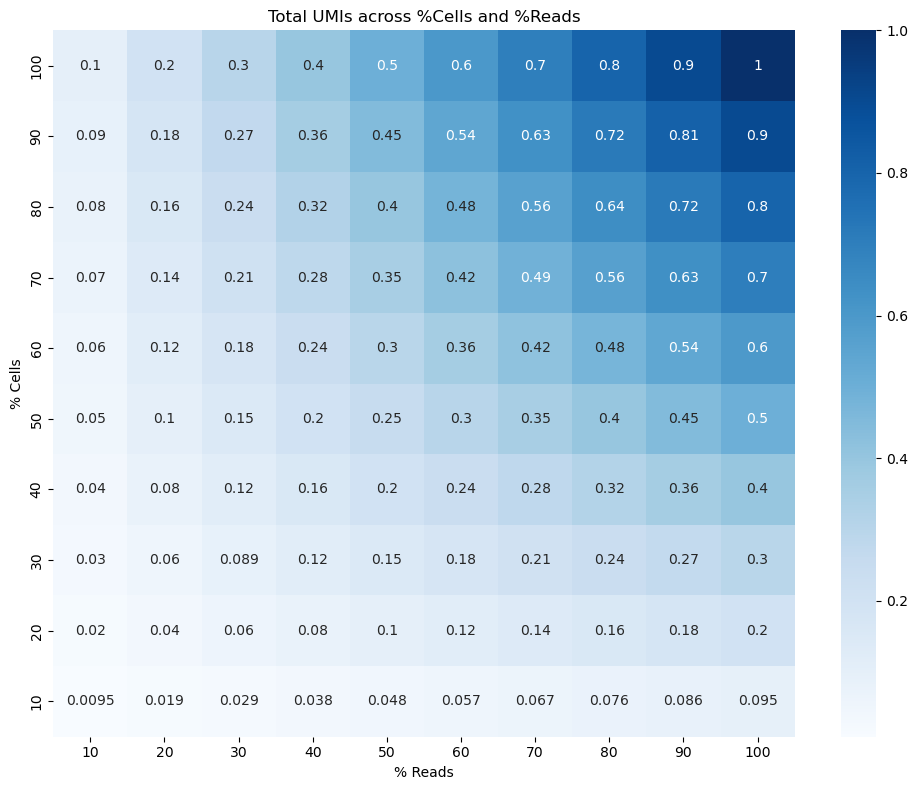

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Split tuple keys into two new columns
summary_df[["cells_frac", "reads_frac"]] = pd.DataFrame(summary_df["sampling_key"].tolist(), index=summary_df.index)

# Strip strings and convert to integers for sorting (optional but recommended)
summary_df["cells_frac"] = summary_df["cells_frac"].str.replace("pct_cells", "", regex=False).astype(int)
summary_df["reads_frac"] = summary_df["reads_frac"].str.replace("pct_reads", "", regex=False).astype(int)
summary_df["umi_percent"] = summary_df["umis"] / summary_df["umis"].max()

# Pivot table for heatmap
heatmap_data = summary_df.pivot(index="cells_frac", columns="reads_frac", values="umi_percent")
heatmap_data = heatmap_data.sort_index(ascending=False)  # Cells descending (Y axis)
heatmap_data = heatmap_data[sorted(heatmap_data.columns)]  # Reads ascending (X axis)

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True,  cmap="Blues")
plt.title("Total UMIs across %Cells and %Reads")
plt.xlabel("% Reads")
plt.ylabel("% Cells")
plt.tight_layout()
plt.show()
